# Actividad 2. Descubriendo patrones de tráfico con datos reales

**Materia:** TC2035 — Diseño de Redes Neuronales y Aprendizaje Profundo  
**Modalidad:** Individual  
**Nombre completo:** Jorge Raúl Martínez Ramírez  
**Matrícula:** A01286802
**Grupo:** 301
**Fecha de entrega:** 23 de noviembre de 2026

## Introducción

El reto de SEMEX consiste en recomendar tiempos de verde (*splits*) para una intersección a partir de las condiciones del tránsito. Antes de entrenar una red neuronal, sin embargo, es indispensable entender qué miden los datos, cómo se organizan y qué patrones contienen.

En este notebook se analizan los volúmenes vehiculares del estudio realizado en la intersección 01 del Distrito Tec (Av. Eugenio Garza Sada – Av. Fernando García Roel). El trabajo se organiza en cuatro partes: exploración de los datos, selección y visualización de tres movimientos, normalización Min-Max y conexión de los hallazgos con una futura MLP. El análisis se realizó con **Polars** y **Matplotlib** a partir de los archivos **Parquet** ya generados; no se vuelve a leer el Excel original.


## Datos utilizados y organización del notebook

Los datos están organizados por intersección y por periodo. Para la intersección 01 se cuenta con tres carpetas:

| Carpeta | Periodo medido | Hora de máxima demanda (HMD) | Volumen en HMD |
|---|---|---|---|
| `mañana` | 07:00–10:00 | 08:00–09:00 | 1,771 veh |
| `mediodia` | 12:00–15:00 | 13:45–14:45 | 2,287 veh |
| `tarde` | 17:00–20:00 | 17:15–18:15 | 2,372 veh |

Dentro de cada carpeta se encuentran tres tipos de archivo:

- `1.parquet` … `14.parquet`: un archivo por movimiento vehicular, con el desglose por tipo de vehículo en intervalos de 15 minutos.
- `vol_dir.parquet`: resumen por movimiento para la hora de máxima demanda (incluye totales, porcentajes, FHMD y porcentaje de vehículos pesados).
- `hora_max.parquet`: total de toda la intersección en cada intervalo de 15 minutos y acumulado por hora.

> **Nota sobre los nombres de los periodos.** El croquis llama “tarde” al periodo de 13:45–14:45 y “noche” al de 17:15–18:15. En los archivos Parquet esas carpetas se llaman `mediodia` y `tarde`, respectivamente. Para evitar confusiones, en este notebook se usa el nombre de la carpeta pero siempre se indica el rango horario. Los totales de 1,771; 2,287 y 2,372 veh coinciden exactamente con el croquis, lo que confirma que se trata de la intersección 01.


In [1]:
%matplotlib inline

from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from IPython.display import display

pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_cols(20)
pl.Config.set_fmt_str_lengths(60)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
})


In [2]:
BASE = Path("datos") / "Eugenio Garza Sada - Fernando García"
assert BASE.exists(), f"No se encontró la carpeta de datos: {BASE.resolve()}"

PERIODOS = ["mañana", "mediodia", "tarde"]

PERIODO_INFO = {
    "mañana":   {"etiqueta": "Mañana (07:00–10:00)",    "hmd": "08:00–09:00"},
    "mediodia": {"etiqueta": "Mediodía (12:00–15:00)",  "hmd": "13:45–14:45"},
    "tarde":    {"etiqueta": "Tarde (17:00–20:00)",     "hmd": "17:15–18:15"},
}
PERIODO_ORDEN = {"mañana": 0, "mediodia": 1, "tarde": 2}

# Movimientos seleccionados: los tres de mayor demanda en los tres periodos.
MOVS = [1, 7, 12]
MOV_CORTO = {1: "M1", 7: "M7", 12: "M12"}
ETIQUETA_A_MOV = {v: k for k, v in MOV_CORTO.items()}

MOV_INFO = {
    1:  "M1 · Del Estado → Av. Fernando García Roel",
    7:  "M7 · Av. Fernando García Roel (Tec) → norte",
    12: "M12 · Av. Eugenio Garza Sada → sur",
}
COLORES = {MOV_CORTO[1]: "#1b9e77", MOV_CORTO[7]: "#d95f02", MOV_CORTO[12]: "#7570b3"}


In [3]:
print(f"Intersección analizada: {BASE.name}\n")
for periodo in PERIODOS:
    carpeta = BASE / periodo
    archivos_mov = sorted(
        [p for p in carpeta.glob("*.parquet") if p.stem.isdigit()],
        key=lambda p: int(p.stem),
    )
    print(f"{PERIODO_INFO[periodo]['etiqueta']}")
    print("  Movimientos disponibles:", ", ".join(p.stem for p in archivos_mov))
    print("  Resúmenes: vol_dir.parquet, hora_max.parquet")


Intersección analizada: Eugenio Garza Sada - Fernando García

Mañana (07:00–10:00)
  Movimientos disponibles: 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14
  Resúmenes: vol_dir.parquet, hora_max.parquet
Mediodía (12:00–15:00)
  Movimientos disponibles: 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14
  Resúmenes: vol_dir.parquet, hora_max.parquet
Tarde (17:00–20:00)
  Movimientos disponibles: 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14
  Resúmenes: vol_dir.parquet, hora_max.parquet


## Parte 1. Exploración y comprensión de los datos

**Propósito:** identificar qué información contiene el archivo antes de procesarla. Primero se revisa la estructura de un archivo de movimiento y, después, los resúmenes por movimiento y por intersección.


In [4]:
mov1_manana = pl.read_parquet(BASE / "mañana" / "1.parquet")
print("Dimensiones (filas, columnas):", mov1_manana.shape)
print("Columnas:", mov1_manana.columns)
print("Valores nulos en todo el archivo:", mov1_manana.null_count().sum_horizontal().item())
display(mov1_manana.head(12))


Dimensiones (filas, columnas): (12, 17)
Columnas: ['Hora Inferior', 'Hora Superior', 'Automoviles', 'Camionetas', 'BTR', 'B', 'Bicicletas', 'C-2', 'C-3', 'C-4', 'C-5', 'C-6', 'C-7', 'C-8', 'C-9', 'Motos', 'Total']
Valores nulos en todo el archivo: 0


Hora Inferior,Hora Superior,Automoviles,Camionetas,BTR,B,Bicicletas,C-2,C-3,C-4,C-5,C-6,C-7,C-8,C-9,Motos,Total
str,str,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32
"""07:00:00""","""07:15:00""",39,0,0,0,0,0,0,0,0,0,0,0,0,0,39
"""07:15:00""","""07:30:00""",59,0,0,0,0,0,0,0,0,0,0,0,0,0,59
"""07:30:00""","""07:45:00""",86,0,0,0,0,0,0,0,0,0,0,0,0,0,86
"""07:45:00""","""08:00:00""",60,0,0,0,0,0,0,0,0,0,0,0,0,0,60
"""08:00:00""","""08:15:00""",71,0,0,0,0,1,0,0,0,0,0,0,0,0,72
"""08:15:00""","""08:30:00""",57,0,0,0,0,0,0,0,0,0,0,0,0,0,57
"""08:30:00""","""08:45:00""",88,0,0,0,0,1,0,0,0,0,0,0,0,0,89
"""08:45:00""","""09:00:00""",72,0,0,0,0,1,0,0,0,0,0,0,0,0,73
"""09:00:00""","""09:15:00""",75,0,0,0,0,0,0,0,0,0,0,0,0,0,75


In [5]:
columnas_numericas = mov1_manana.select(pl.exclude("Hora Inferior", "Hora Superior"))
display(columnas_numericas.describe())


statistic,Automoviles,Camionetas,BTR,B,Bicicletas,C-2,C-3,C-4,C-5,C-6,C-7,C-8,C-9,Motos,Total
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",69.833333,0.0,0.0,0.0,0.0,0.333333,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,70.166667
"""std""",13.979422,0.0,0.0,0.0,0.0,0.492366,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,14.147491
"""min""",39.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,39.0
"""25%""",60.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,60.0
"""50%""",73.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,74.0
"""75%""",76.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,76.0
"""max""",88.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,89.0


In [6]:
resumen = pl.concat([
    pl.read_parquet(BASE / periodo / "vol_dir.parquet").with_columns(
        pl.lit(periodo).alias("Periodo")
    )
    for periodo in PERIODOS
]).with_columns(
    pl.col("Periodo").replace_strict(PERIODO_ORDEN).alias("_orden")
)

display(
    resumen.sort(["_orden", "Movimiento"])
    .select(["Periodo", "Movimiento", "A", "BTR", "B", "BICI", "C", "M", "Total", "FHMD", "HV_pct"])
)


Periodo,Movimiento,A,BTR,B,BICI,C,M,Total,FHMD,HV_pct
str,i32,i32,i32,i32,i32,i32,i32,i32,f64,f64
"""mañana""",1,288,0,0,0,3,0,291,0.817416,0.010309
"""mañana""",2,174,0,0,5,0,0,179,0.745833,0.0
"""mañana""",3,78,0,0,0,0,0,78,0.8125,0.0
"""mañana""",4,28,0,5,0,0,0,33,0.75,0.151515
"""mañana""",5,51,0,4,0,0,0,55,0.763889,0.072727
"""mañana""",6,97,0,33,1,0,0,131,0.744318,0.251908
"""mañana""",7,236,0,9,0,0,0,245,0.92803,0.036735
"""mañana""",8,52,0,0,0,0,0,52,0.764706,0.0
"""mañana""",9,56,0,0,1,0,0,57,0.838235,0.0


In [7]:
hora_max = pl.concat([
    pl.read_parquet(BASE / periodo / "hora_max.parquet").with_columns(
        pl.lit(periodo).alias("Periodo")
    )
    for periodo in PERIODOS
]).with_columns(
    pl.col("Periodo").replace_strict(PERIODO_ORDEN).alias("_orden")
)

resumen_interseccion = (
    hora_max.group_by(["Periodo", "_orden"])
    .agg([
        pl.col("Total Por Horas").max().alias("HMD_total_veh"),
        pl.col("Total").max().alias("max_15min_veh"),
        pl.col("Total").sum().alias("total_periodo_veh"),
    ])
    .sort("_orden")
)
display(resumen_interseccion)


Periodo,_orden,HMD_total_veh,max_15min_veh,total_periodo_veh
str,i64,i32,i32,i32
"""mañana""",0,1771,465,4664
"""mediodia""",1,2287,593,6331
"""tarde""",2,2372,634,6659


In [8]:
registros_calidad = []
for periodo in PERIODOS:
    for mov in range(1, 15):
        df = pl.read_parquet(BASE / periodo / f"{mov}.parquet")
        registros_calidad.append({
            "Periodo": periodo,
            "Archivo": f"{mov}.parquet",
            "Filas": df.height,
            "Nulos": df.null_count().sum_horizontal().item(),
            "Intervalos_unicos": df.select(
                pl.struct("Hora Inferior", "Hora Superior")
            ).n_unique(),
        })

calidad = (
    pl.DataFrame(registros_calidad)
    .with_columns(pl.col("Periodo").replace_strict(PERIODO_ORDEN).alias("_orden"))
    .group_by(["Periodo", "_orden"])
    .agg([
        pl.len().alias("archivos"),
        pl.col("Filas").min().alias("filas_min"),
        pl.col("Filas").max().alias("filas_max"),
        pl.col("Nulos").sum().alias("nulos_totales"),
        pl.col("Intervalos_unicos").max().alias("intervalos_unicos"),
    ])
    .sort("_orden")
)
display(calidad)


Periodo,_orden,archivos,filas_min,filas_max,nulos_totales,intervalos_unicos
str,i64,u32,i64,i64,i64,i64
"""mañana""",0,14,12,12,0,12
"""mediodia""",1,14,12,12,0,12
"""tarde""",2,14,12,12,0,12


In [9]:
chequeo = []
for periodo in PERIODOS:
    suma_movs = sum(
        pl.read_parquet(BASE / periodo / f"{m}.parquet")["Total"].sum()
        for m in range(1, 15)
    )
    suma_hora_max = pl.read_parquet(BASE / periodo / "hora_max.parquet")["Total"].sum()
    chequeo.append({
        "Periodo": periodo,
        "Suma movimientos 1–14": suma_movs,
        "Suma hora_max": suma_hora_max,
        "Coincide": suma_movs == suma_hora_max,
    })

display(pl.DataFrame(chequeo))


Periodo,Suma movimientos 1–14,Suma hora_max,Coincide
str,i64,i64,bool
"""mañana""",4664,4664,true
"""mediodia""",6331,6331,true
"""tarde""",6659,6659,true


### Interpretación 1. Comprendiendo los datos

- **¿Qué representa cada registro o fila que utilizarás?** En cada archivo `N.parquet` una fila representa un intervalo de 15 minutos de un movimiento vehicular (por ejemplo, 08:00–08:15). En `vol_dir.parquet` una fila representa el resumen de un movimiento durante la hora de máxima demanda. En `hora_max.parquet` una fila representa un intervalo de 15 minutos, pero sumando todos los movimientos de la intersección.

- **¿Qué variables identificaste?** `Hora Inferior` y `Hora Superior` delimitan el intervalo. Los conteos por tipo de vehículo son `Automoviles`, `Camionetas`, `BTR` (bus de tránsito rápido), `B` (autobús), `Bicicletas`, `C-2` a `C-9` (vehículos de carga por número de ejes) y `Motos`. La columna `Total` suma todos los tipos. En `vol_dir.parquet` aparecen además `Movimiento`, los totales agregados `A` (autos ligeros), `BTR`, `B`, `BICI`, `C` y `M`, sus porcentajes, `FHMD` (factor de hora de máxima demanda) y `HV_pct` (porcentaje de vehículos pesados).

- **¿Qué unidades tienen los volúmenes?** Los conteos de los archivos por movimiento están en **vehículos por intervalo de 15 minutos** (veh/15 min). Los totales de `vol_dir.parquet` corresponden a **vehículos por hora** durante la HMD, y `hora_max.parquet` reporta tanto el total de cada intervalo de 15 minutos como el acumulado de la hora.

- **¿Qué información podría ser útil para analizar el comportamiento del tráfico?** La evolución temporal de cada movimiento, la proporción de autos frente a carga, buses, motos y bicicletas, la demanda acumulada, la hora de máxima demanda y el reparto modal. Esta información permite comparar movimientos y detectar patrones de entrada y salida.

- **¿Encontraste datos faltantes, encabezados especiales o información que requiera limpieza?** Los conteos numéricos no presentan valores nulos. La columna `Extra_1` de `vol_dir.parquet` solo tiene un valor en la primera fila y el resto es nulo, por lo que no se utilizó. Los archivos 13 y 14 contienen movimientos adicionales de bajo volumen que no aparecen en `vol_dir.parquet`; sin embargo, la suma de los 14 archivos coincide exactamente con `hora_max.parquet` en los tres periodos (verificado arriba). También fue necesario homologar los nombres de los periodos con el croquis y convertir las horas a texto legible. No se requirió una limpieza profunda porque los Parquet ya venían normalizados en tipos y sin nulos.


## Parte 2. Selección y visualización de movimientos vehiculares

**Propósito:** observar cómo cambia el volumen vehicular en distintos movimientos de la intersección.

Se seleccionaron los movimientos **1, 7 y 12** porque son los tres de mayor demanda en los tres periodos y porque el croquis permite identificarlos con claridad:

| Movimiento | Volumen en HMD (mañana) | Interpretación con el croquis |
|---|---|---|
| **M1** | 291 veh | Ingresa desde **Del Estado** (poniente) y sale hacia **Av. Fernando García Roel** (oriente). |
| **M7** | 245 veh | Ingresa desde **Av. Fernando García Roel** (lado Tec) y sale hacia el **norte**. |
| **M12** | 328 veh | Ingresa desde **Av. Eugenio Garza Sada** (norponiente) y sale hacia el **sur**. |

En `vol_dir.parquet`, el campo `Total` de estos movimientos coincide con las etiquetas 291, 245 y 328 del croquis de la mañana, lo que confirma la selección.


In [10]:
def cargar_movimiento(periodo: str, mov: int) -> pl.DataFrame:
    """Carga un movimiento y lo deja en formato largo (una fila por intervalo)."""
    return (
        pl.read_parquet(BASE / periodo / f"{mov}.parquet")
        .select("Hora Inferior", "Hora Superior", pl.col("Total").alias("Volumen"))
        .with_columns(
            pl.lit(mov).alias("Movimiento"),
            pl.lit(periodo).alias("Periodo"),
            (
                pl.col("Hora Inferior").str.slice(0, 5)
                + "–"
                + pl.col("Hora Superior").str.slice(0, 5)
            ).alias("Intervalo"),
        )
        .with_columns(
            pl.col("Movimiento").replace_strict(MOV_CORTO).alias("Etiqueta"),
            pl.col("Periodo").replace_strict(PERIODO_ORDEN).alias("_orden"),
        )
    )


df_movs = (
    pl.concat([cargar_movimiento(periodo, mov) for periodo in PERIODOS for mov in MOVS])
    .sort(["_orden", "Hora Inferior"])
)

display(df_movs.select(["Periodo", "Hora Inferior", "Hora Superior", "Intervalo", "Etiqueta", "Volumen"]).head(15))


Periodo,Hora Inferior,Hora Superior,Intervalo,Etiqueta,Volumen
str,str,str,str,str,i32
"""mañana""","""07:00:00""","""07:15:00""","""07:00–07:15""","""M7""",39
"""mañana""","""07:00:00""","""07:15:00""","""07:00–07:15""","""M12""",73
"""mañana""","""07:00:00""","""07:15:00""","""07:00–07:15""","""M1""",39
"""mañana""","""07:15:00""","""07:30:00""","""07:15–07:30""","""M12""",63
"""mañana""","""07:15:00""","""07:30:00""","""07:15–07:30""","""M1""",59
"""mañana""","""07:15:00""","""07:30:00""","""07:15–07:30""","""M7""",32
"""mañana""","""07:30:00""","""07:45:00""","""07:30–07:45""","""M1""",86
"""mañana""","""07:30:00""","""07:45:00""","""07:30–07:45""","""M7""",39
"""mañana""","""07:30:00""","""07:45:00""","""07:30–07:45""","""M12""",50


In [11]:
tabla_manana = (
    df_movs.filter(pl.col("Periodo") == "mañana")
    .pivot(values="Volumen", index=["Hora Inferior", "Hora Superior"], on="Etiqueta")
    .sort("Hora Inferior")
    .select(["Hora Inferior", "Hora Superior", "M1", "M7", "M12"])
    .rename({"Hora Inferior": "Hora inicio", "Hora Superior": "Hora fin"})
)

display(tabla_manana)


Hora inicio,Hora fin,M1,M7,M12
str,str,i32,i32,i32
"""07:00:00""","""07:15:00""",39,39,73
"""07:15:00""","""07:30:00""",59,32,63
"""07:30:00""","""07:45:00""",86,39,50
"""07:45:00""","""08:00:00""",60,74,83
"""08:00:00""","""08:15:00""",72,62,81
"""08:15:00""","""08:30:00""",57,57,76
"""08:30:00""","""08:45:00""",89,60,96
"""08:45:00""","""09:00:00""",73,66,75
"""09:00:00""","""09:15:00""",75,59,48


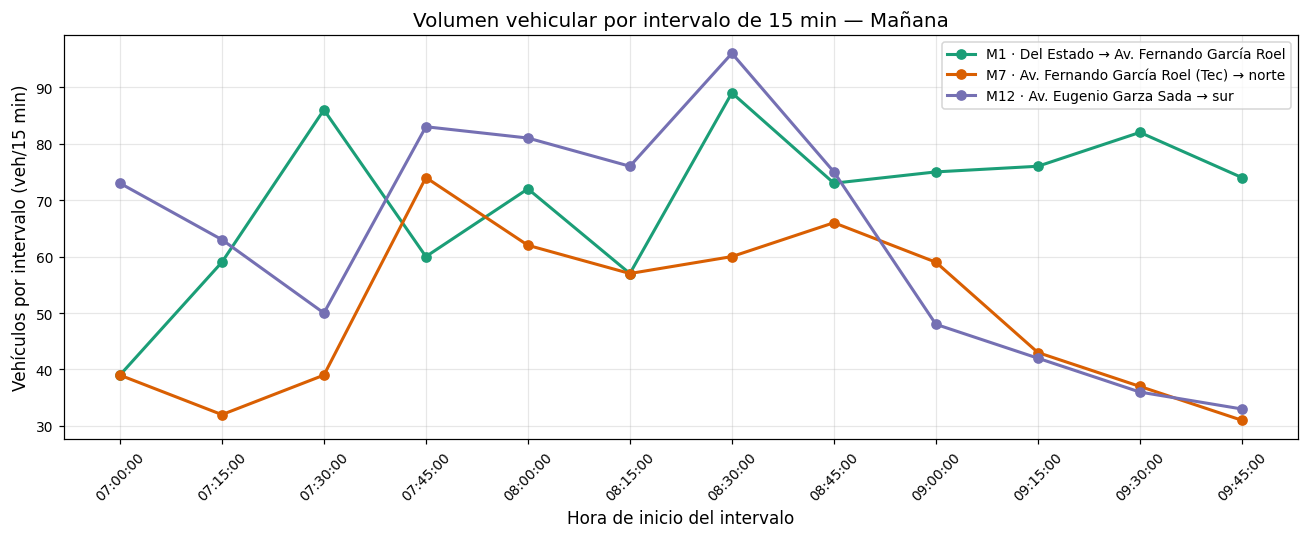

In [12]:
fig, ax = plt.subplots(figsize=(12, 5))

for etiqueta in ["M1", "M7", "M12"]:
    grupo = (
        df_movs.filter((pl.col("Periodo") == "mañana") & (pl.col("Etiqueta") == etiqueta))
        .sort("Hora Inferior")
    )
    mov = ETIQUETA_A_MOV[etiqueta]
    ax.plot(
        grupo["Hora Inferior"].to_list(),
        grupo["Volumen"].to_list(),
        marker="o",
        linewidth=2,
        color=COLORES[etiqueta],
        label=MOV_INFO[mov],
    )

ax.set_title("Volumen vehicular por intervalo de 15 min — Mañana")
ax.set_xlabel("Hora de inicio del intervalo")
ax.set_ylabel("Vehículos por intervalo (veh/15 min)")
ax.yaxis.set_major_locator(MultipleLocator(10))
ax.grid(alpha=0.3)
ax.tick_params(axis="x", rotation=45)
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()


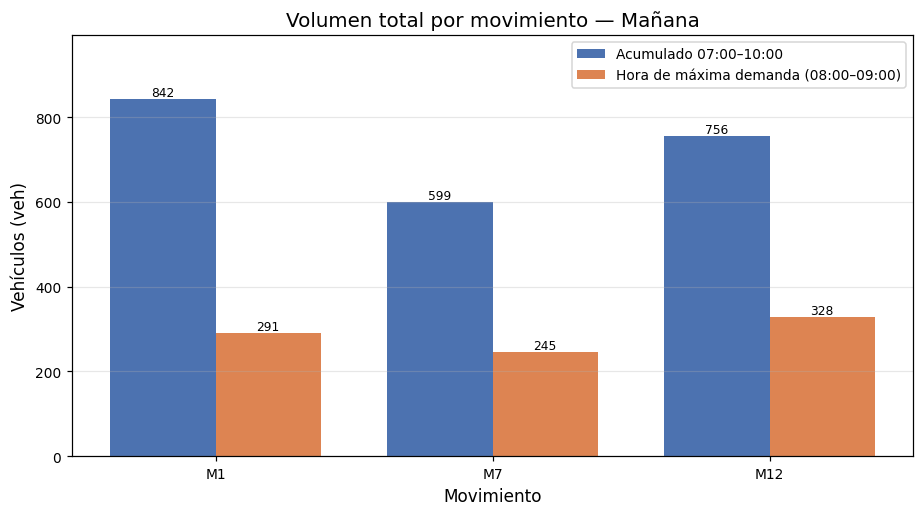

In [13]:
acumulado_manana = (
    df_movs.filter(pl.col("Periodo") == "mañana")
    .group_by("Etiqueta")
    .agg(pl.col("Volumen").sum().alias("Acumulado 07:00–10:00"))
    .with_columns(pl.col("Etiqueta").replace_strict({"M1": 0, "M7": 1, "M12": 2}).alias("_orden"))
)

hmd_manana = (
    resumen.filter((pl.col("Periodo") == "mañana") & pl.col("Movimiento").is_in(MOVS))
    .select("Movimiento", pl.col("Total").alias("HMD 08:00–09:00"))
    .with_columns(pl.col("Movimiento").replace_strict(MOV_CORTO).alias("Etiqueta"))
)

totales_movs = (
    acumulado_manana.join(hmd_manana, on="Etiqueta", how="left")
    .sort("_orden")
)

x = np.arange(len(totales_movs))
ancho = 0.38

fig, ax = plt.subplots(figsize=(8.5, 4.8))
barras_1 = ax.bar(
    x - ancho / 2,
    totales_movs["Acumulado 07:00–10:00"].to_list(),
    ancho,
    label="Acumulado 07:00–10:00",
    color="#4c72b0",
)
barras_2 = ax.bar(
    x + ancho / 2,
    totales_movs["HMD 08:00–09:00"].to_list(),
    ancho,
    label="Hora de máxima demanda (08:00–09:00)",
    color="#dd8452",
)

for barras in (barras_1, barras_2):
    for barra in barras:
        ax.annotate(
            f"{int(barra.get_height())}",
            (barra.get_x() + barra.get_width() / 2, barra.get_height()),
            ha="center",
            va="bottom",
            fontsize=8,
        )

ax.set_xticks(x)
ax.set_xticklabels(totales_movs["Etiqueta"].to_list())
ax.set_xlabel("Movimiento")
ax.set_ylabel("Vehículos (veh)")
ax.set_title("Volumen total por movimiento — Mañana")
ax.set_ylim(0, totales_movs["Acumulado 07:00–10:00"].max() * 1.18)
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()


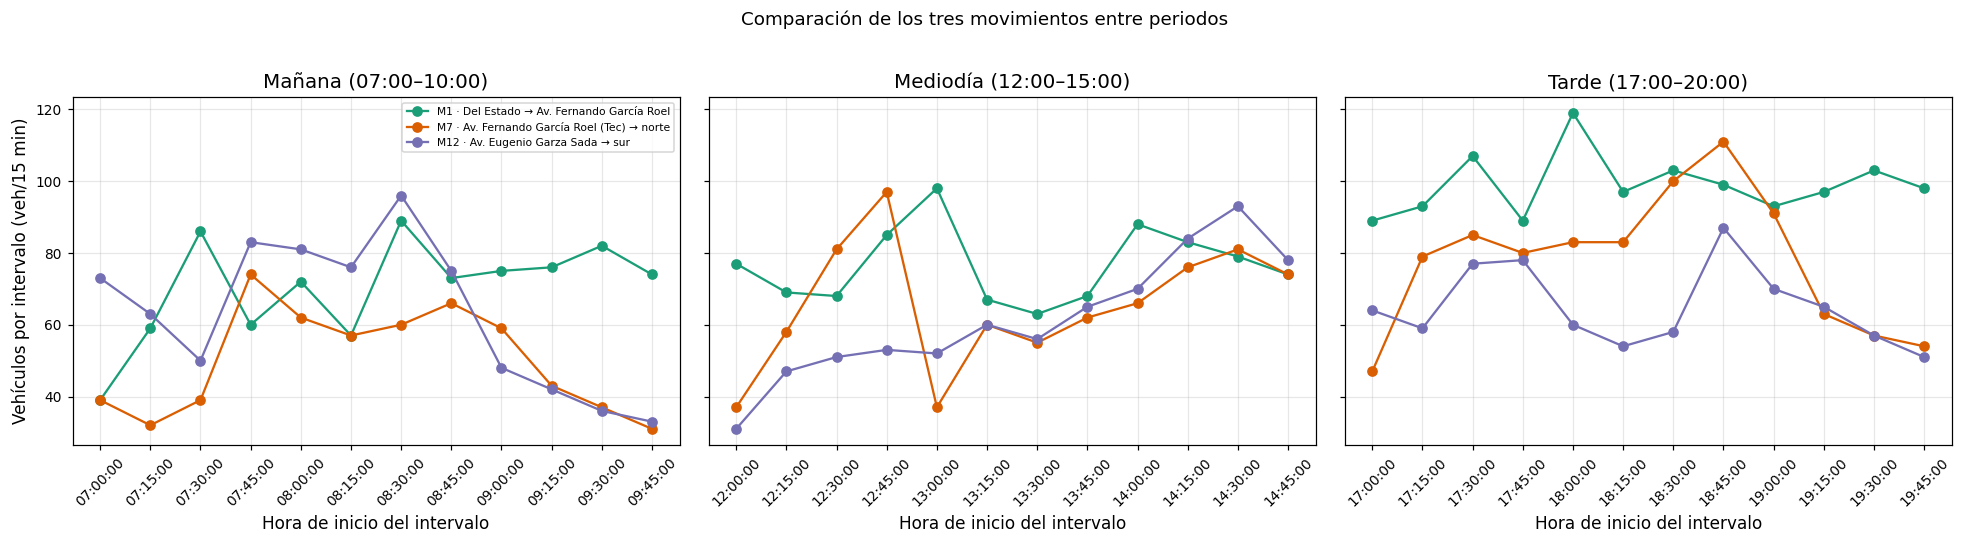

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), sharey=True)

for ax, periodo in zip(axes, PERIODOS):
    for etiqueta in ["M1", "M7", "M12"]:
        grupo = (
            df_movs.filter((pl.col("Periodo") == periodo) & (pl.col("Etiqueta") == etiqueta))
            .sort("Hora Inferior")
        )
        mov = ETIQUETA_A_MOV[etiqueta]
        ax.plot(
            grupo["Hora Inferior"].to_list(),
            grupo["Volumen"].to_list(),
            marker="o",
            color=COLORES[etiqueta],
            label=MOV_INFO[mov],
        )
    ax.set_title(PERIODO_INFO[periodo]["etiqueta"])
    ax.set_xlabel("Hora de inicio del intervalo")
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", rotation=45)

axes[0].set_ylabel("Vehículos por intervalo (veh/15 min)")
axes[0].legend(fontsize=7, loc="upper right")
fig.suptitle("Comparación de los tres movimientos entre periodos", y=1.02)
fig.tight_layout()
plt.show()


### Interpretación 2. Comportamiento del tráfico

- **¿Cuál de los tres movimientos presenta mayor volumen?** Depende de la métrica. En la **hora de máxima demanda** de la mañana, M12 es el mayor (328 veh), seguido de M1 (291) y M7 (245). En el **acumulado de las tres horas**, M1 pasa al primer lugar (842 veh), seguido de M12 (756) y M7 (599). Es decir, M12 concentra la demanda pico, mientras que M1 sostiene un volumen alto durante más tiempo.

- **¿En qué intervalo se observa la mayor demanda?** En la mañana, M1 y M12 alcanzan su máximo en **08:30–08:45** (89 y 96 veh/15 min, respectivamente), mientras que M7 lo alcanza antes, en **07:45–08:00** (74 veh/15 min). En el mediodía los máximos se reparten: M1 en 13:00–13:15 (98), M7 en 12:45–13:00 (97) y M12 en 14:30–14:45 (93). Por la tarde, M1 llega a 119 veh/15 min en 18:00–18:15 y M7 a 111 en 18:45–19:00.

- **¿Los tres movimientos se comportan de manera similar?** Comparten un patrón general de “hora pico”: la demanda sube al inicio del periodo, se mantiene alta y luego disminuye. Sin embargo, no son idénticos. M7 tiene un pico matutino más temprano y cae más rápido; M1 se mantiene alto hasta las 10:00; M12 cae abruptamente después de las 08:30. Por la tarde, M1 domina la mayor parte del periodo, aunque M7 lo supera brevemente entre 18:45 y 19:00 (111 vs 99 veh/15 min).

- **¿Qué diferencias encuentras entre ellos?** Diferencias de magnitud (M12 es el mayor en la HMD matutina; M1 es el mayor en el acumulado y en la tarde), de sincronización (M7 se adelanta) y de composición (M1 es casi totalmente autos ligeros —288 de 291—, M12 tiene la mayor proporción de autobuses —18 de 328— y M7 combina 236 autos con 9 autobuses). También cambia la estabilidad: M1 es más sostenido y M12 más variable.

- **¿Por qué podría ser importante conocer estas diferencias al distribuir los tiempos de verde?** Porque el verde debe asignarse en función de la demanda real de cada acceso y movimiento. Si se reparte por igual, un movimiento con 328 veh/h recibiría el mismo verde que uno con 245, generando filas y demoras innecesarias. Conocer el pico y su duración permite diseñar planes por franja horaria, priorizar los movimientos críticos y coordinar fases con la demanda de buses o peatones.


## Parte 3. Normalización de los datos

**Propósito:** comprender por qué la escala de las variables puede ser importante al entrenar una red neuronal.

Se aplica normalización **Min-Max** a los volúmenes de M1, M7 y M12:

$$
x_{\text{normalizado}} = \frac{x - x_{\min}}{x_{\max} - x_{\min}}
$$

La normalización se calcula **por movimiento** usando los 36 intervalos de los tres periodos (12 por periodo). Así, cada movimiento queda en el intervalo \([0, 1]\) y se conserva su forma temporal. Si un movimiento fuera constante (\(x_{\max} = x_{\min}\)), la división sería indeterminada; en el código ese caso se asigna a \(0.0\) y se documenta que la variable no aporta variabilidad.


In [15]:
xmin = pl.col("Volumen").min().over("Etiqueta")
xmax = pl.col("Volumen").max().over("Etiqueta")

df_norm = df_movs.with_columns(
    pl.when(xmax == xmin)
    .then(0.0)
    .otherwise((pl.col("Volumen") - xmin) / (xmax - xmin))
    .alias("Volumen_norm")
)

display(
    df_norm.group_by("Etiqueta")
    .agg([
        pl.col("Volumen").min().alias("min_original"),
        pl.col("Volumen").max().alias("max_original"),
        pl.col("Volumen_norm").min().alias("min_normalizado"),
        pl.col("Volumen_norm").max().alias("max_normalizado"),
    ])
    .sort("Etiqueta")
)


Etiqueta,min_original,max_original,min_normalizado,max_normalizado
str,i32,i32,f64,f64
"""M1""",39,119,0.0,1.0
"""M12""",31,96,0.0,1.0
"""M7""",31,111,0.0,1.0


In [16]:
original = (
    df_norm.filter(pl.col("Periodo") == "mañana")
    .pivot(values="Volumen", index=["Hora Inferior", "Hora Superior"], on="Etiqueta")
    .sort("Hora Inferior")
    .rename({"M1": "M1_original", "M7": "M7_original", "M12": "M12_original"})
)

normalizado = (
    df_norm.filter(pl.col("Periodo") == "mañana")
    .pivot(values="Volumen_norm", index=["Hora Inferior", "Hora Superior"], on="Etiqueta")
    .sort("Hora Inferior")
    .rename({"M1": "M1_normalizado", "M7": "M7_normalizado", "M12": "M12_normalizado"})
)

tabla_normalizada = (
    original.join(normalizado, on=["Hora Inferior", "Hora Superior"])
    .select([
        "Hora Inferior", "Hora Superior",
        "M1_original", "M1_normalizado",
        "M7_original", "M7_normalizado",
        "M12_original", "M12_normalizado",
    ])
    .rename({"Hora Inferior": "Hora inicio", "Hora Superior": "Hora fin"})
)

display(tabla_normalizada)


Hora inicio,Hora fin,M1_original,M1_normalizado,M7_original,M7_normalizado,M12_original,M12_normalizado
str,str,i32,f64,i32,f64,i32,f64
"""07:00:00""","""07:15:00""",39,0.0,39,0.1,73,0.646154
"""07:15:00""","""07:30:00""",59,0.25,32,0.0125,63,0.492308
"""07:30:00""","""07:45:00""",86,0.5875,39,0.1,50,0.292308
"""07:45:00""","""08:00:00""",60,0.2625,74,0.5375,83,0.8
"""08:00:00""","""08:15:00""",72,0.4125,62,0.3875,81,0.769231
"""08:15:00""","""08:30:00""",57,0.225,57,0.325,76,0.692308
"""08:30:00""","""08:45:00""",89,0.625,60,0.3625,96,1.0
"""08:45:00""","""09:00:00""",73,0.425,66,0.4375,75,0.676923
"""09:00:00""","""09:15:00""",75,0.45,59,0.35,48,0.261538


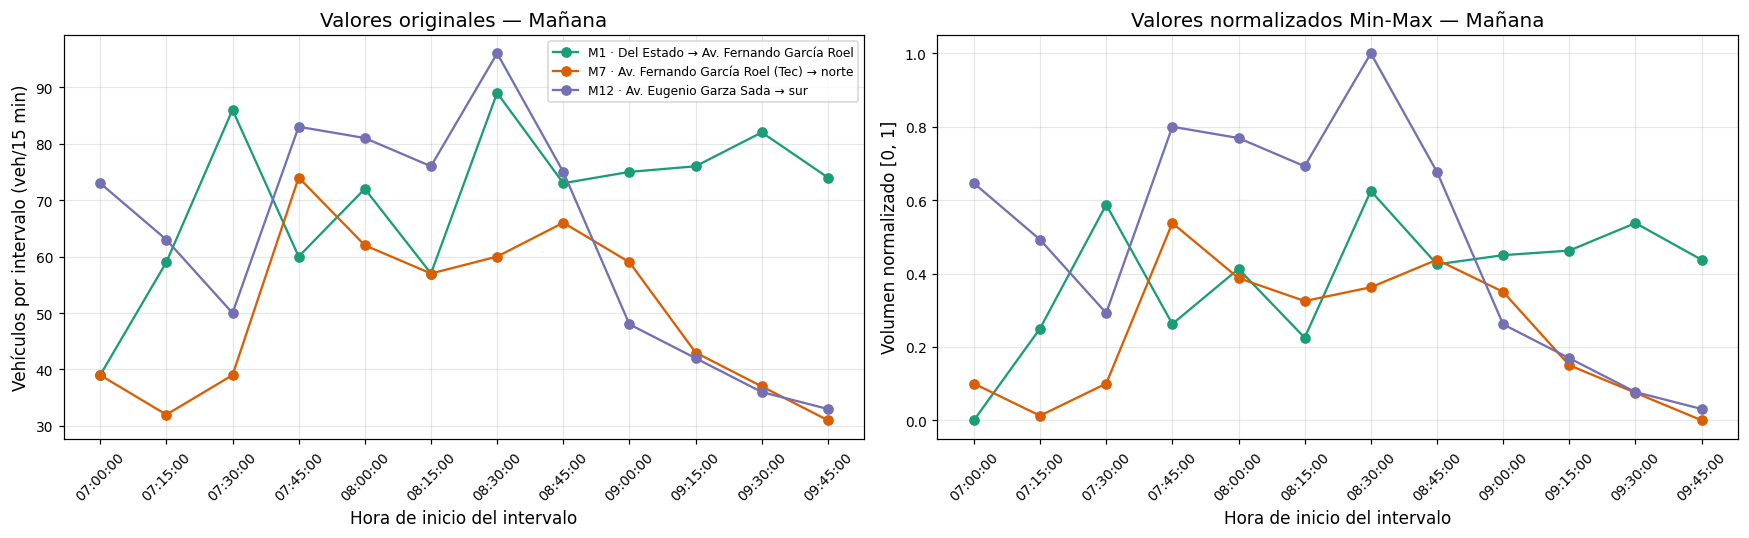

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for etiqueta in ["M1", "M7", "M12"]:
    grupo = (
        df_norm.filter((pl.col("Periodo") == "mañana") & (pl.col("Etiqueta") == etiqueta))
        .sort("Hora Inferior")
    )
    mov = ETIQUETA_A_MOV[etiqueta]
    axes[0].plot(
        grupo["Hora Inferior"].to_list(),
        grupo["Volumen"].to_list(),
        marker="o",
        color=COLORES[etiqueta],
        label=MOV_INFO[mov],
    )
    axes[1].plot(
        grupo["Hora Inferior"].to_list(),
        grupo["Volumen_norm"].to_list(),
        marker="o",
        color=COLORES[etiqueta],
        label=MOV_INFO[mov],
    )

axes[0].set_title("Valores originales — Mañana")
axes[0].set_ylabel("Vehículos por intervalo (veh/15 min)")
axes[1].set_title("Valores normalizados Min-Max — Mañana")
axes[1].set_ylabel("Volumen normalizado [0, 1]")

for ax in axes:
    ax.set_xlabel("Hora de inicio del intervalo")
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", rotation=45)

axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()


### Interpretación 3. Normalización

- **¿Qué cambió después de normalizar los datos?** Los valores pasaron de estar en veh/15 min (aproximadamente 31–119) a un rango común de 0 a 1. Ya no importa la magnitud absoluta de cada movimiento: lo que se compara es la posición relativa de cada intervalo dentro de su propio rango. La escala del eje vertical ahora es adimensional.

- **¿Se conservaron los patrones de crecimiento y disminución?** Sí. Min-Max es una transformación lineal y monótona: si un valor era mayor que otro dentro del mismo movimiento, sigue siéndolo después de normalizar. Los picos, valles y la forma de las curvas se mantienen; solo cambia la escala. Por eso la gráfica normalizada “se parece” a la original, pero las tres series quedan más comparables visualmente.

- **¿Por qué puede ser útil normalizar variables antes de entrenar una MLP?** Porque el descenso del gradiente y los optimizadores trabajan mejor cuando las entradas tienen escalas parecidas. Con volúmenes de distinta magnitud, una variable puede dominar la actualización de los pesos, producir gradientes desbalanceados o saturar funciones de activación. Normalizar mejora la condición numérica del problema, acelera la convergencia y hace que la tasa de aprendizaje sea más fácil de ajustar.

- **¿Normalizar significa que todos los movimientos tienen el mismo volumen?** No. Cada movimiento se normaliza con **su propio** mínimo y máximo. Un valor de 1 significa “el máximo de ese movimiento”, no “el mismo volumen absoluto que los demás”. En nuestros datos, el máximo original de M1 en la mañana es 89, el de M7 es 74 y el de M12 es 96; después de normalizar, los tres llegan a 1 en su propio pico, aunque en veh/15 min sean distintos. Por eso, si el objetivo es predecir un split que dependa del volumen absoluto, conviene conservar también la escala original o normalizar todas las variables con una referencia común.

- **Caso de volumen constante:** si \(x_{\max} = x_{\min}\), el denominador es cero. En el código se detecta con `pl.when(xmax == xmin)` y se asigna \(0.0\). Esa variable no aporta información discriminante (todas sus observaciones son iguales), por lo que también podría eliminarse del modelo.


## Parte 4. Identificación de patrones para una futura MLP

**Propósito:** conectar el análisis de tráfico con los conceptos de redes neuronales estudiados en clase.

A partir de los datos explorados, se construye una tabla de posibles variables de entrada. La tabla incluye la hora, los volúmenes de los tres movimientos, el volumen total de esos movimientos y la participación relativa de cada uno. Se agrega una columna de etiqueta objetivo vacía para dejar explícito que **todavía no disponemos de los splits recomendados**.


In [18]:
features_manana = (
    df_movs.filter(pl.col("Periodo") == "mañana")
    .pivot(values="Volumen", index=["Hora Inferior"], on="Etiqueta")
    .sort("Hora Inferior")
    .select(["Hora Inferior", "M1", "M7", "M12"])
    .with_columns(
        pl.col("Hora Inferior").str.slice(0, 2).cast(pl.Int8).alias("hora"),
        (pl.col("M1") + pl.col("M7") + pl.col("M12")).alias("vol_total_3mov"),
    )
    .with_columns(
        (pl.col("M1") / pl.col("vol_total_3mov")).alias("share_M1"),
        (pl.col("M7") / pl.col("vol_total_3mov")).alias("share_M7"),
        (pl.col("M12") / pl.col("vol_total_3mov")).alias("share_M12"),
        pl.lit(None, dtype=pl.Float64).alias("split_verde_objetivo"),
    )
    .select([
        "Hora Inferior", "hora", "M1", "M7", "M12",
        "vol_total_3mov", "share_M1", "share_M7", "share_M12",
        "split_verde_objetivo",
    ])
)

display(features_manana)
print("Observaciones de entrada:", features_manana.height)
print("Etiquetas objetivo disponibles:", features_manana["split_verde_objetivo"].drop_nulls().len())


Hora Inferior,hora,M1,M7,M12,vol_total_3mov,share_M1,share_M7,share_M12,split_verde_objetivo
str,i8,i32,i32,i32,i32,f64,f64,f64,f64
"""07:00:00""",7,39,39,73,151,0.258278,0.258278,0.483444,null
"""07:15:00""",7,59,32,63,154,0.383117,0.207792,0.409091,null
"""07:30:00""",7,86,39,50,175,0.491429,0.222857,0.285714,null
"""07:45:00""",7,60,74,83,217,0.276498,0.341014,0.382488,null
"""08:00:00""",8,72,62,81,215,0.334884,0.288372,0.376744,null
"""08:15:00""",8,57,57,76,190,0.3,0.3,0.4,null
"""08:30:00""",8,89,60,96,245,0.363265,0.244898,0.391837,null
"""08:45:00""",8,73,66,75,214,0.341121,0.308411,0.350467,null
"""09:00:00""",9,75,59,48,182,0.412088,0.324176,0.263736,null


Observaciones de entrada: 12
Etiquetas objetivo disponibles: 0


### Interpretación 4. Conexión con las redes neuronales

- **¿Qué datos de este estudio utilizarías como entradas de una MLP?** Los volúmenes por movimiento en el intervalo actual y en los intervalos anteriores (por ejemplo, M1, M7 y M12), el volumen total de la intersección, la participación relativa de cada movimiento, la hora del día, el periodo (mañana, mediodía o tarde), el día de la semana y el porcentaje de vehículos pesados o buses. También podrían incluirse variables de movimientos aguas arriba si estuvieran disponibles.

- **¿Qué te gustaría que la red aprendiera a predecir?** El objetivo del reto SEMEX es recomendar los **tiempos de verde o splits** de cada fase/movimiento. Una MLP podría aprender un mapeo desde las condiciones de tráfico (volúmenes, hora, composición) hacia esos splits, o bien predecir primero la demanda futura y después usar un optimizador de semáforos.

- **¿Disponemos actualmente de las etiquetas necesarias para predecir splits recomendados?** No. Los datos contienen volúmenes observados, pero no incluyen los tiempos de verde aplicados ni los splits recomendados por un experto. La columna `split_verde_objetivo` está vacía precisamente para evidenciarlo. Para entrenar un modelo supervisado haría falta obtener esos planes de SEMEX, generarlos con un simulador/optimizador o construirlos con reglas de ingeniería de tránsito.

- **¿Qué diferencia existe entre identificar un patrón en una gráfica y demostrar que una red neuronal realmente aprendió ese patrón?** Ver un pico en una gráfica es un análisis descriptivo: nosotros interpretamos la forma de la curva. Que una red lo haya aprendido implica que, a partir de entradas nuevas, produce predicciones cercanas a los valores reales. Eso se demuestra con métricas cuantitativas (MAE, RMSE, \(R^2\)), curvas de pérdida de entrenamiento y validación, análisis de residuos y comparaciones contra una línea base. Una red puede memorizar los datos de entrenamiento sin generalizar.

- **¿Cómo comprobarías, en una etapa posterior, que el modelo funciona con datos que no utilizó durante el entrenamiento?** Separaría los datos en entrenamiento, validación y prueba, idealmente por días o periodos completos para evitar fuga de información temporal. Ajustaría los hiperparámetros con validación y reportaría el desempeño final una sola vez en el conjunto de prueba. También usaría validación cruzada temporal, compararía contra modelos simples y revisaría si el error se mantiene estable en horas pico y periodos no vistos.

**Limitaciones de esta etapa.** El estudio corresponde a una sola intersección y a tres periodos de observación; no hay información de días distintos, clima, incidentes ni planes semafóricos. Por ello, los patrones identificados son un punto de partida, no una base suficiente para entrenar un modelo predictivo robusto.


## Conclusión: ¿qué aprendí sobre los datos de tráfico?

En los tres periodos, el tráfico de la intersección 01 se concentra en horas pico y cambia según el movimiento. Los movimientos 1, 7 y 12 son los de mayor demanda, pero no se comportan igual. En la mañana, M12 alcanza el mayor volumen en la hora de máxima demanda (328 veh), mientras que M1 tiene el mayor acumulado de las tres horas (842 veh) y se mantiene alto hasta las 10:00. M7 presenta un pico más temprano y cae más rápido. Por la tarde, M1 vuelve a dominar.

La normalización Min-Max llevó los volúmenes a una escala común de 0 a 1 y permitió comparar las formas de las curvas sin que la magnitud absoluta dominara. Aprendí que normalizar no iguala los volúmenes: cada movimiento conserva su propio mínimo y máximo, y un valor de 1 solo indica el pico de ese movimiento. Este paso será importante al entrenar una MLP, pues escalas muy distintas dificultan el descenso del gradiente.

Antes de entrenar una red es indispensable comprender los datos: qué representa una fila, qué unidades tienen los volúmenes, qué movimientos son críticos y qué información falta. En el reto SEMEX, los volúmenes y su evolución temporal pueden servir como entradas, pero aún no contamos con las etiquetas de splits recomendados. Este análisis es una base sólida, mas no sustituye la recolección de etiquetas ni la validación con datos no vistos.
